In [3]:
!pip install diffusers transformers accelerate torch torchvision

In [1]:
import diffusers
import transformers

diffusers.__version__

'0.33.1'

In [2]:
transformers.__version__

'4.52.4'

In [6]:
!pip install diffusers==0.33.1
!pip install transformers==4.52.4

  Using cached transformers-4.52.4-py3-none-any.whl.metadata (38 kB)
  Using cached huggingface_hub-0.36.2-py3-none-any.whl.metadata (15 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 20.7 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.2
    Uninstalling tokenizers-0.23.2:
      Successfully uninstalled tokenizers-0.23.2
  Attempting uninstall: transformers
    Found existing installation: transformers 5.19.0
    Uninstalling transformers-5.19.0:
      Successfully uninstalled transformers-5.19.0
ERROR: pip's dependency resolver does not currently take into account all the pac

In [3]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [4]:
from diffusers import StableDiffusionPipeline, StableDiffusionInpaintPipeline
from PIL import Image
import matplotlib.pyplot as plt

def display_image(image):
    plt.imshow(image)
    plt.axis('off')
    plt.show()

Additional test done:

- Seed reproducibility:
manual_seed(42) change to 7
- Step count:
change num_steps to 50
-

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Text-to-Image pipeline loaded.
Generating image for prompt: 'A photo of man riding a horse in the moon wearing astronaut outfits'


  0%|          | 0/30 [00:00<?, ?it/s]

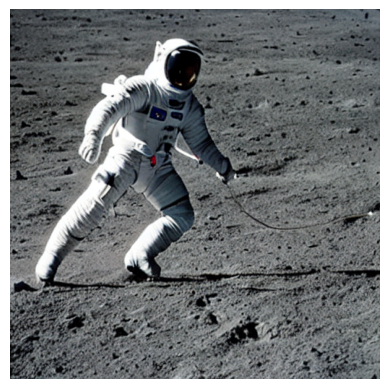

Image saved as generated_defect_0.png


In [8]:
# --- 1.1 파이프라인 로드 ---
model_id_text2img = "stable-diffusion-v1-5/stable-diffusion-v1-5"
pipe_text2img = StableDiffusionPipeline.from_pretrained(model_id_text2img, torch_dtype=torch.float16)
pipe_text2img = pipe_text2img.to(device)
print("Text-to-Image pipeline loaded.")

# --- 1.2 프롬프트 정의 및 이미지 생성 ---
prompt_defect = "A photo of man riding a horse in the moon wearing astronaut outfits"
negative_prompt = "blurry, deformed, cartoon, painting, illustration, normal, no defect"

# 파라미터 설정
num_steps = 30
guidance_scale_val = 8.5
num_images_per_prompt = 1 # 한 번에 여러 개 생성 가능

print(f"Generating image for prompt: '{prompt_defect}'")
# seed 고정으로 재현성 확보 (선택 사항)
generator = torch.Generator(device=device).manual_seed(7)

with torch.autocast("cuda"): # float16 연산 시
    generated_images = pipe_text2img(
        prompt_defect,
        negative_prompt=negative_prompt,
        num_inference_steps=num_steps,
        guidance_scale=guidance_scale_val,
        num_images_per_prompt=num_images_per_prompt,
        generator=generator
    ).images

# --- 1.3 결과 확인 및 저장 ---
for i, image in enumerate(generated_images):
    display_image(image)
    try:
        image.save(f"generated_defect_{i}.png")
        print(f"Image saved as generated_defect_{i}.png")
    except Exception as e:
        print(f"Error saving image: {e}")


###Test 2
- use different image

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Inpainting pipeline loaded.
Using placeholder initial image and mask.


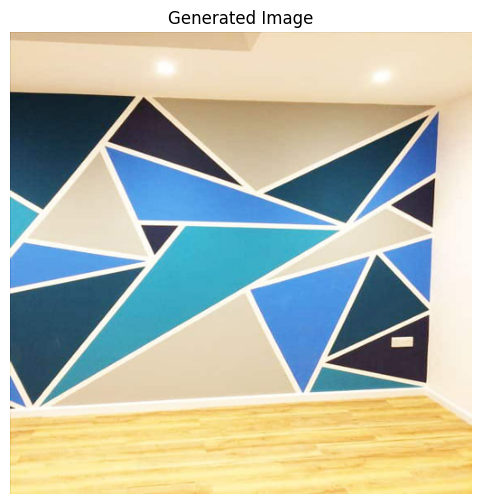

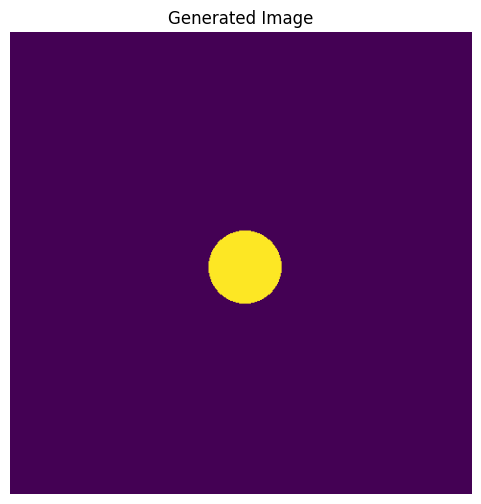

Inpainting with prompt: 'peeling paint and rust'


  0%|          | 0/50 [00:00<?, ?it/s]

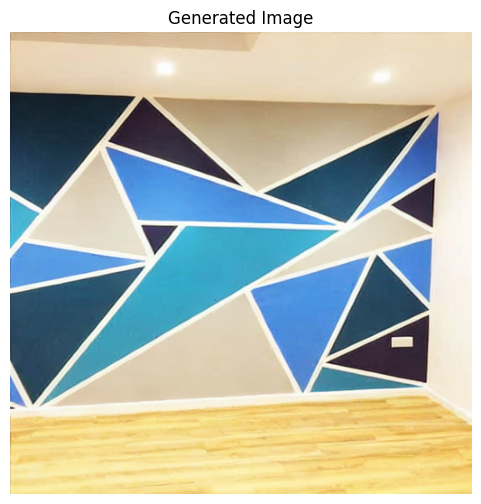

Image saved as inpainted_defect_0.png


In [17]:
# --- 2.1 파이프라인 로드 ---
# Inpainting 전용 모델 사용
model_id_inpaint = "stable-diffusion-v1-5/stable-diffusion-inpainting" # 또는 다른 inpainting 모델
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(model_id_inpaint, torch_dtype=torch.float16, variant="fp16")
    pipe_inpaint = pipe_inpaint.to(device)
    print("Inpainting pipeline loaded.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}. Skipping inpainting part or use a general pipeline.")
    pipe_inpaint = None # 예외 처리

if pipe_inpaint:
    # --- 2.2 원본 이미지 및 마스크 준비 ---
    init_image = Image.open("product1.jpg").convert("RGB").resize((512, 512)) # 밝은 회색 배경
    mask_image = Image.new("L", (512, 512), "black")
    from PIL import ImageDraw
    draw = ImageDraw.Draw(mask_image)
    draw.ellipse(((220, 220), (300, 300)), fill="white") # 중앙 흰색 원형 마스크
    print("Using placeholder initial image and mask.")
    display_image(init_image)
    display_image(mask_image)


    # --- 2.3 프롬프트 정의 및 이미지 생성 ---
    prompt_inpaint_defect = "peeling paint and rust"
    negative_prompt_inpaint = "clean, shiny, new, blurry"

    print(f"Inpainting with prompt: '{prompt_inpaint_defect}'")
    with torch.autocast("cuda"):
        inpainted_images = pipe_inpaint(
            prompt=prompt_inpaint_defect,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt_inpaint,
            num_inference_steps=50, # Inpainting은 조금 더 많은 step이 필요할 수 있음
            guidance_scale=7.5
        ).images

    # --- 2.4 결과 확인 및 저장 ---
    for i, image in enumerate(inpainted_images):
        display_image(image)
        try:
            image.save(f"inpainted_defect_{i}.png")
            print(f"Image saved as inpainted_defect_{i}.png")
        except Exception as e:
            print(f"Error saving image: {e}")

# TODO: 다양한 원본 이미지, 마스크, 프롬프트로 실험해보세요!
#       예: 실제 정상 제품 이미지에 사용자가 직접 그린 마스크 적용

###Test 3

- mask size and position:
change ellipse_box size

Using device: cuda


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Inpainting pipeline loaded with stable-diffusion-v1-5/stable-diffusion-inpainting.
Image loaded and resized to 512x512.


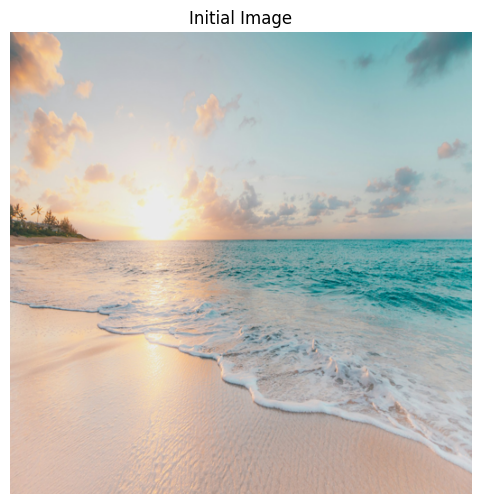

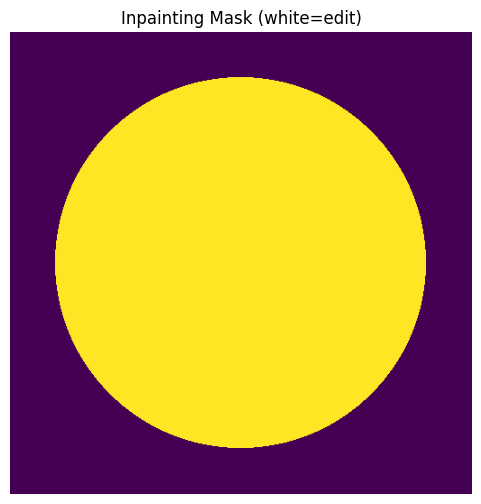

Running inpainting with prompt: A treasure chest buried in the sand


  0%|          | 0/50 [00:00<?, ?it/s]

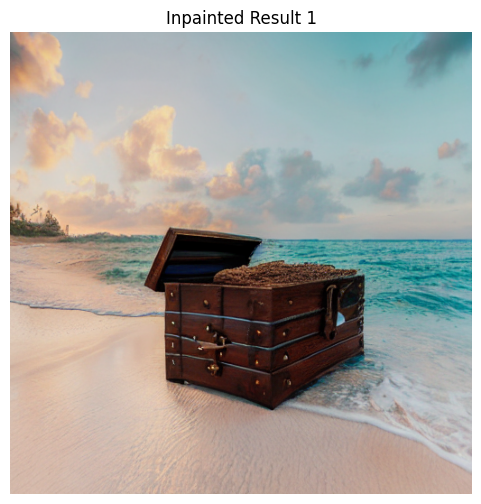

Saved: result_inpainted_0.png


In [19]:
import torch
from diffusers import StableDiffusionInpaintPipeline
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import requests
from io import BytesIO

# --- 1. 디바이스 설정 ---
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# --- 2. 이미지 시각화 함수 ---
def display_image(image, title="Generated Image"):
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')
    plt.show()

# --- 3. 파이프라인 로딩 ---
model_id_inpaint = "stable-diffusion-v1-5/stable-diffusion-inpainting"
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
        model_id_inpaint,
        torch_dtype=torch.float16 if device == "cuda" else torch.float32,
        variant="fp16"
    )
    pipe_inpaint = pipe_inpaint.to(device)
    print(f"Inpainting pipeline loaded with {model_id_inpaint}.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}")
    pipe_inpaint = None

# --- 4. 이미지와 마스크 준비 ---
if pipe_inpaint:
    # 이미지 로드
    image_url = "https://images.unsplash.com/photo-1507525428034-b723cf961d3e?q=80&w=2070&auto=format&fit=crop"
    try:
        response = requests.get(image_url)
        response.raise_for_status()
        init_image = Image.open(BytesIO(response.content)).convert("RGB").resize((512, 512))
        print("Image loaded and resized to 512x512.")
    except Exception as e:
        print(f"Image load failed: {e}. Using placeholder image.")
        init_image = Image.new("RGB", (512, 512))
        draw = ImageDraw.Draw(init_image)
        draw.rectangle([0, 0, 512, 280], fill="skyblue")
        draw.rectangle([0, 280, 512, 512], fill="goldenrod")
        draw.ellipse([400, 60, 440, 100], fill="gold")

    # 마스크 생성 (중앙 타원형)
    mask_image = Image.new("L", (512, 512), 0)  # 검정 배경
    draw = ImageDraw.Draw(mask_image)
    ellipse_box = [50, 50,460, 460]  # 대략 중앙 타원 (너비 300, 높이 400)
    draw.ellipse(ellipse_box, fill=255)  # 흰색 영역을 인페인팅할 영역으로

    # 이미지 확인
    display_image(init_image, "Initial Image")
    display_image(mask_image, "Inpainting Mask (white=edit)")

    # --- 5. 프롬프트 정의 ---
    prompt = "A treasure chest buried in the sand"
    negative_prompt = "blurry, deformed, cartoon, illustration, watermark, text, signature, extra limbs"

    print(f"Running inpainting with prompt: {prompt}")

    generator = torch.Generator(device=device).manual_seed(1234)

    # --- 6. 인페인팅 수행 ---
    if device == "cuda":
        with torch.autocast("cuda"):
            result = pipe_inpaint(
                prompt=prompt,
                image=init_image,
                mask_image=mask_image,
                negative_prompt=negative_prompt,
                guidance_scale=8.5,
                num_inference_steps=50,
                generator=generator
            )
    else:
        result = pipe_inpaint(
            prompt=prompt,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt,
            guidance_scale=8.5,
            num_inference_steps=50,
            generator=generator
        )

    # --- 7. 결과 출력 및 저장 ---
    if result and result.images:
        for i, out_img in enumerate(result.images):
            display_image(out_img, f"Inpainted Result {i+1}")
            out_img.save(f"result_inpainted_{i}.png")
            print(f"Saved: result_inpainted_{i}.png")
    else:
        print("No images returned from inpainting.")

else:
    print("Pipeline not loaded. Cannot run inpainting.")
